In [1]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import RobustScaler, PowerTransformer, OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.pipeline import Pipeline

In [2]:
columns = [
    "age",
    "sex",
    "cp",
    "trestbps",
    "chol",
    "fbs",
    "restecg",
    "thalach",
    "exang",
    "oldpeak",
    "slope",
    "ca",
    "thal",
    "num"
]

df = pd.read_csv("../data/raw/processed.cleveland.csv", names=columns, header=None)
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        303 non-null    str    
 12  thal      303 non-null    str    
 13  num       303 non-null    int64  
dtypes: float64(11), int64(1), str(2)
memory usage: 35.0 KB


In [4]:
df.num.describe()

count    303.000000
mean       0.937294
std        1.228536
min        0.000000
25%        0.000000
50%        0.000000
75%        2.000000
max        4.000000
Name: num, dtype: float64

In [5]:
df["num"] = (df["num"] > 0).astype(int)

df.rename(columns={"num": "target"}, inplace=True)


/tmp/ipykernel_9736/59669037.py:3: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.rename(columns={"num": "target"}, inplace=True)


In [6]:
df["target"].describe()

count    303.000000
mean       0.458746
std        0.499120
min        0.000000
25%        0.000000
50%        0.000000
75%        1.000000
max        1.000000
Name: target, dtype: float64

In [7]:
df.isnull().sum()

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

In [8]:
df["ca"]=df["ca"].replace("?", np.nan)

In [9]:
df["ca"] = df["ca"].astype(float)

In [10]:
df["target"].value_counts()

target
0    164
1    139
Name: count, dtype: int64

In [11]:
df["thal"].unique()

<ArrowStringArray>
['6.0', '3.0', '7.0', '?']
Length: 4, dtype: str

In [12]:
df["thal"]=df["thal"].replace("?", np.nan)

In [13]:
df["thal"] = df["thal"].astype(float)

In [14]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  target    303 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 33.3 KB


In [15]:
df.isnull().sum()

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64

In [16]:
X = df.drop(columns=["target"])
y = df["target"]

In [17]:
print(y.value_counts())
print(y.value_counts(normalize=True) * 100)

target
0    164
1    139
Name: count, dtype: int64
target
0    54.125413
1    45.874587
Name: proportion, dtype: float64


In [18]:
numerical_features = [
    "age",
    "chol",
    "oldpeak",
    "thalach",
    "trestbps"
]

categorical_features = [
    "sex",
    "cp",
    "fbs",
    "restecg",
    "exang",
    "slope",
    "ca",
    "thal"
]

In [19]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [20]:
print("Training distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting distribution:")
print(y_test.value_counts(normalize=True))

Training distribution:
target
0    0.541322
1    0.458678
Name: proportion, dtype: float64

Testing distribution:
target
0    0.540984
1    0.459016
Name: proportion, dtype: float64


In [21]:
transformer = PowerTransformer(
    method="yeo-johnson",
    standardize=True
)

In [22]:
numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("transformer", PowerTransformer(
        method="yeo-johnson",
        standardize=True
    ))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numerical_transformer, numerical_features),
    ("cat", categorical_transformer, categorical_features)
])

In [23]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

models = {
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "SVM": SVC(probability=True),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42)
}

In [24]:

baseline_models = {}

for name, model in models.items():

    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    baseline_models[name] = pipeline

In [25]:

baseline_results = []
baseline_predictions = {}

for name, pipeline in baseline_models.items():

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    baseline_predictions[name] = y_prob

    baseline_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

baseline_results_df = pd.DataFrame(baseline_results)

baseline_results_df.sort_values(
    by="ROC-AUC",
    ascending=False
)

/home/archit/Documents/CodeAlphaInternship/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.868852,0.833333,0.892857,0.862069,0.959957
1,SVM,0.885246,0.862069,0.892857,0.877193,0.953463
3,Random Forest,0.901639,0.843750,0.964286,0.900000,0.944264
2,Decision Tree,0.737705,0.687500,0.785714,0.733333,0.741342


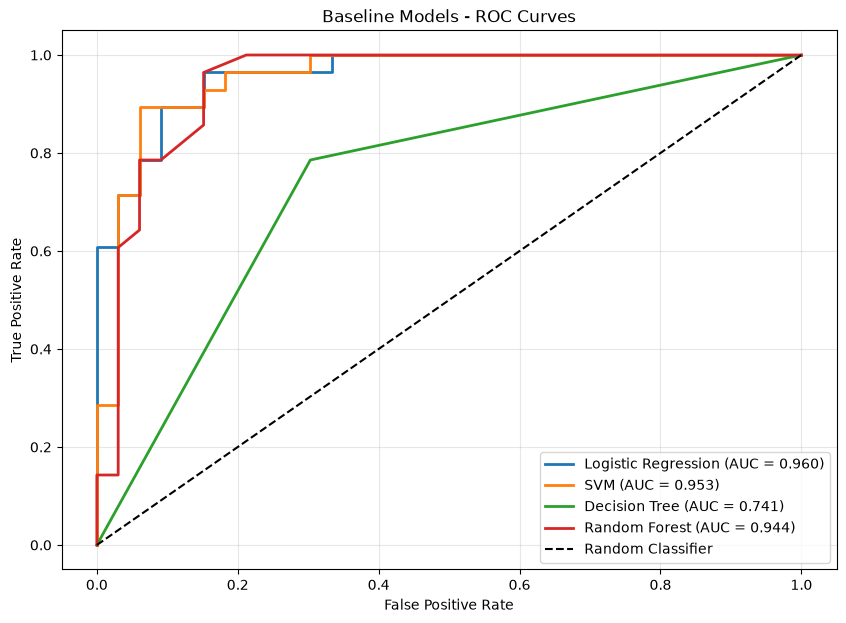

In [26]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

plt.figure(figsize=(10, 7))

for name, y_prob in baseline_predictions.items():

    fpr, tpr, thresholds = roc_curve(y_test, y_prob)
    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{name} (AUC = {roc_auc:.3f})"
    )

plt.plot([0, 1], [0, 1], "k--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Baseline Models - ROC Curves")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

# SMOTE


In [27]:


smote_models = {}

for name, model in models.items():

    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("smote", SMOTE(random_state=42)),
        ("classifier", model)
    ])

    smote_models[name] = pipeline

In [28]:
smote_results = []
smote_predictions = {}

for name, pipeline in smote_models.items():

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    smote_predictions[name] = y_prob

    smote_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

smote_results_df = pd.DataFrame(smote_results)

smote_results_df.sort_values(
    by="ROC-AUC",
    ascending=False
)

/home/archit/Documents/CodeAlphaInternship/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.885246,0.838710,0.928571,0.881356,0.956710
1,SVM,0.885246,0.862069,0.892857,0.877193,0.952381
3,Random Forest,0.885246,0.838710,0.928571,0.881356,0.943723
2,Decision Tree,0.737705,0.657895,0.892857,0.757576,0.749459


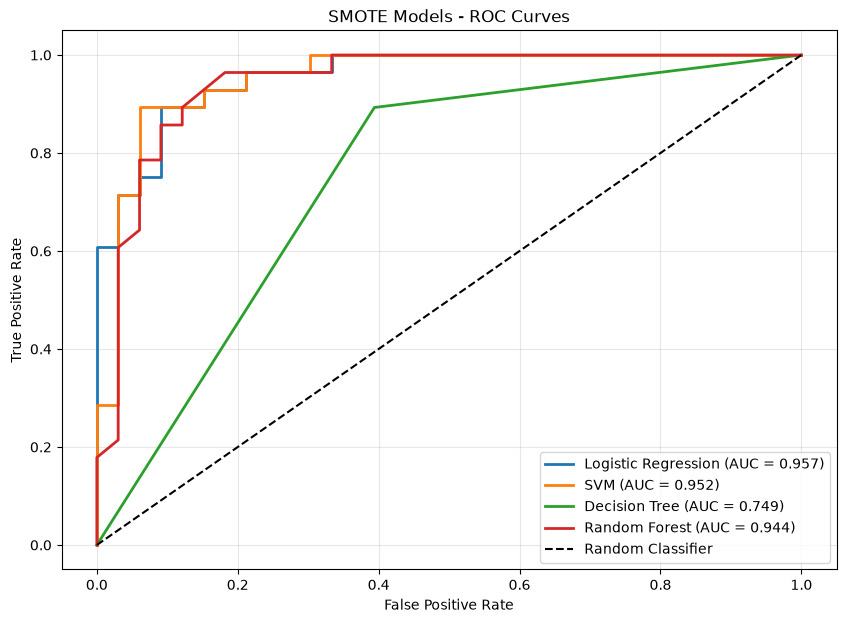

In [29]:
plt.figure(figsize=(10, 7))

for name, y_prob in smote_predictions.items():

    fpr, tpr, thresholds = roc_curve(y_test, y_prob)
    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{name} (AUC = {roc_auc:.3f})"
    )

plt.plot([0, 1], [0, 1], "k--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("SMOTE Models - ROC Curves")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

# metrics of each model without tuning

In [30]:
baseline_results_df["Technique"] = "Baseline"
smote_results_df["Technique"] = "SMOTE"

comparison_df = pd.concat(
    [baseline_results_df, smote_results_df],
    ignore_index=True
)

comparison_df.sort_values(
    by="ROC-AUC",
    ascending=False
)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Technique
0,Logistic Regression,0.868852,0.833333,0.892857,0.862069,0.959957,Baseline
4,Logistic Regression,0.885246,0.838710,0.928571,0.881356,0.956710,SMOTE
1,SVM,0.885246,0.862069,0.892857,0.877193,0.953463,Baseline
5,SVM,0.885246,0.862069,0.892857,0.877193,0.952381,SMOTE
3,Random Forest,0.901639,0.843750,0.964286,0.900000,0.944264,Baseline
7,Random Forest,0.885246,0.838710,0.928571,0.881356,0.943723,SMOTE
6,Decision Tree,0.737705,0.657895,0.892857,0.757576,0.749459,SMOTE
2,Decision Tree,0.737705,0.687500,0.785714,0.733333,0.741342,Baseline


In [31]:
metrics = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]

comparison = baseline_results_df.merge(
    smote_results_df,
    on="Model",
    suffixes=("_Baseline", "_SMOTE")
)

for metric in metrics:
    comparison[f"{metric}_Change"] = (
        comparison[f"{metric}_SMOTE"] -
        comparison[f"{metric}_Baseline"]
    )

comparison[
    ["Model"] +
    [f"{m}_Change" for m in metrics]
]

,Model,Accuracy_Change,Precision_Change,Recall_Change,F1_Change,ROC-AUC_Change
0,Logistic Regression,0.016393,0.005376,0.035714,0.019287,-0.003247
1,SVM,0.000000,0.000000,0.000000,0.000000,-0.001082
2,Decision Tree,0.000000,-0.029605,0.107143,0.024242,0.008117
3,Random Forest,-0.016393,-0.005040,-0.035714,-0.018644,-0.000541


- Logistic Regression -> SMOTE
- SVM -> baseline
- Decision Tree -> SMOTE
- Random Forest -> baseline

# hyper parm tuning

In [32]:
import optuna
import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.base import clone

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

/home/archit/Documents/CodeAlphaInternship/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [33]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [34]:
scoring = {
    "f1": "f1",
    "recall": "recall"
}

In [35]:
def objective_lr(trial):

    C = trial.suggest_float("C", 0.001, 100, log=True)

    model = Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("smote", SMOTE(random_state=42)),
        ("classifier", LogisticRegression(
            C=C,
            max_iter=3000,
            solver="liblinear"
        ))
    ])

    scores = cross_validate(
        model, X_train, y_train,
        cv=cv, scoring=scoring
    )

    f1 = scores["test_f1"].mean()
    recall = scores["test_recall"].mean()

    return 0.7 * f1 + 0.3 * recall

In [36]:
def objective_svm(trial):

    C = trial.suggest_float("C", 0.001, 100, log=True)

    kernel = trial.suggest_categorical(
        "kernel", ["linear", "rbf", "poly"]
    )

    gamma = trial.suggest_categorical(
        "gamma", ["scale", "auto"]
    )

    model = Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("classifier", SVC(
            C=C,
            kernel=kernel,
            gamma=gamma,
        ))
    ])

    scores = cross_validate(
        model, X_train, y_train,
        cv=cv, scoring=scoring
    )

    f1 = scores["test_f1"].mean()
    recall = scores["test_recall"].mean()

    return 0.7 * f1 + 0.3 * recall

In [37]:
def objective_dt(trial):

    model = Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("smote", SMOTE(random_state=42)),
        ("classifier", DecisionTreeClassifier(
            max_depth=trial.suggest_int("max_depth", 2, 20),
            min_samples_split=trial.suggest_int(
                "min_samples_split", 2, 20
            ),
            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf", 1, 10
            ),
            criterion=trial.suggest_categorical(
                "criterion", ["gini", "entropy", "log_loss"]
            ),
            random_state=42
        ))
    ])

    scores = cross_validate(
        model, X_train, y_train,
        cv=cv, scoring=scoring
    )

    f1 = scores["test_f1"].mean()
    recall = scores["test_recall"].mean()

    return 0.7 * f1 + 0.3 * recall

In [38]:
def objective_rf(trial):

    model = Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("classifier", RandomForestClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators", 100, 500
            ),
            max_depth=trial.suggest_int(
                "max_depth", 2, 20
            ),
            min_samples_split=trial.suggest_int(
                "min_samples_split", 2, 20
            ),
            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf", 1, 10
            ),
            max_features=trial.suggest_categorical(
                "max_features", ["sqrt", "log2", None]
            ),
            random_state=42,
            n_jobs=-1
        ))
    ])

    scores = cross_validate(
        model, X_train, y_train,
        cv=cv, scoring=scoring
    )

    f1 = scores["test_f1"].mean()
    recall = scores["test_recall"].mean()

    return 0.7 * f1 + 0.3 * recall

In [39]:
objectives = {
    "Logistic Regression": objective_lr,
    "SVM": objective_svm,
    "Decision Tree": objective_dt,
    "Random Forest": objective_rf
}

studies = {}

for name, objective in objectives.items():

    print(f"\nTuning {name}...")

    study = optuna.create_study(
        direction="maximize",
        sampler=optuna.samplers.TPESampler(seed=42)
    )

    study.optimize(objective, n_trials=50)

    studies[name] = study

    print("Best Score:", study.best_value)
    print("Best Parameters:", study.best_params)

[I 2026-10-30 20:34:52,653] A new study created in memory with name: no-name-6f83f1a4-1b73-4427-b702-ff5b33cdfb73



Tuning Logistic Regression...


[I 2026-10-30 20:34:58,464] Trial 0 finished with value: 0.7892407647240208 and parameters: {'C': 0.0745934328572655}. Best is trial 0 with value: 0.7892407647240208.
[I 2026-10-30 20:35:01,817] Trial 1 finished with value: 0.8056891316749759 and parameters: {'C': 56.69849511478853}. Best is trial 1 with value: 0.8056891316749759.
[I 2026-10-30 20:35:04,252] Trial 2 finished with value: 0.8038507478365919 and parameters: {'C': 4.5705630998014515}. Best is trial 1 with value: 0.8056891316749759.
[I 2026-10-30 20:35:06,943] Trial 3 finished with value: 0.8109849180142404 and parameters: {'C': 0.9846738873614566}. Best is trial 3 with value: 0.8109849180142404.
[I 2026-10-30 20:35:10,406] Trial 4 finished with value: 0.7816860274990709 and parameters: {'C': 0.006026889128682512}. Best is trial 3 with value: 0.8109849180142404.
[I 2026-10-30 20:35:18,148] Trial 5 finished with value: 0.7816860274990709 and parameters: {'C': 0.0060252157362038605}. Best is trial 3 with value: 0.810984918014

Best Score: 0.8215362994493429
Best Parameters: {'C': 0.237923278635028}

Tuning SVM...


[I 2026-10-30 20:37:35,032] Trial 0 finished with value: 0.7837327332345159 and parameters: {'C': 0.0745934328572655, 'kernel': 'linear', 'gamma': 'scale'}. Best is trial 0 with value: 0.7837327332345159.
[I 2026-10-30 20:37:37,325] Trial 1 finished with value: 0.4209548936337155 and parameters: {'C': 0.0019517224641449498, 'kernel': 'linear', 'gamma': 'auto'}. Best is trial 0 with value: 0.7837327332345159.
[I 2026-10-30 20:37:40,042] Trial 2 finished with value: 0.7806101524256348 and parameters: {'C': 14.528246637516036, 'kernel': 'linear', 'gamma': 'auto'}. Best is trial 0 with value: 0.7837327332345159.
[I 2026-10-30 20:37:42,180] Trial 3 finished with value: 0.7477249263428817 and parameters: {'C': 0.14445251022763064, 'kernel': 'rbf', 'gamma': 'auto'}. Best is trial 0 with value: 0.7837327332345159.
[I 2026-10-30 20:37:44,237] Trial 4 finished with value: 0.791969766499089 and parameters: {'C': 0.19069966103000435, 'kernel': 'linear', 'gamma': 'scale'}. Best is trial 4 with valu

Best Score: 0.7978941589811154
Best Parameters: {'C': 2.7556354336356597, 'kernel': 'linear', 'gamma': 'scale'}

Tuning Decision Tree...


[I 2026-10-30 20:39:43,764] Trial 0 finished with value: 0.733480033279831 and parameters: {'max_depth': 9, 'min_samples_split': 20, 'min_samples_leaf': 8, 'criterion': 'gini'}. Best is trial 0 with value: 0.733480033279831.
[I 2026-10-30 20:39:46,505] Trial 1 finished with value: 0.7509641723291874 and parameters: {'max_depth': 3, 'min_samples_split': 18, 'min_samples_leaf': 7, 'criterion': 'log_loss'}. Best is trial 1 with value: 0.7509641723291874.
[I 2026-10-30 20:39:49,469] Trial 2 finished with value: 0.682266139657444 and parameters: {'max_depth': 17, 'min_samples_split': 6, 'min_samples_leaf': 2, 'criterion': 'log_loss'}. Best is trial 1 with value: 0.7509641723291874.
[I 2026-10-30 20:39:53,529] Trial 3 finished with value: 0.7316766334276508 and parameters: {'max_depth': 10, 'min_samples_split': 7, 'min_samples_leaf': 7, 'criterion': 'log_loss'}. Best is trial 1 with value: 0.7509641723291874.
[I 2026-10-30 20:39:56,284] Trial 4 finished with value: 0.736924495794061 and para

Best Score: 0.7817340935251856
Best Parameters: {'max_depth': 12, 'min_samples_split': 5, 'min_samples_leaf': 10, 'criterion': 'entropy'}

Tuning Random Forest...


[I 2026-10-30 20:43:31,950] Trial 0 finished with value: 0.7869686686590185 and parameters: {'n_estimators': 250, 'max_depth': 20, 'min_samples_split': 15, 'min_samples_leaf': 6, 'max_features': 'sqrt'}. Best is trial 0 with value: 0.7869686686590185.
[I 2026-10-30 20:43:58,960] Trial 1 finished with value: 0.7890246127149626 and parameters: {'n_estimators': 447, 'max_depth': 13, 'min_samples_split': 15, 'min_samples_leaf': 1, 'max_features': 'sqrt'}. Best is trial 1 with value: 0.7890246127149626.
[I 2026-10-30 20:44:06,637] Trial 2 finished with value: 0.7802793606324832 and parameters: {'n_estimators': 172, 'max_depth': 5, 'min_samples_split': 7, 'min_samples_leaf': 6, 'max_features': None}. Best is trial 1 with value: 0.7890246127149626.
[I 2026-10-30 20:44:13,553] Trial 3 finished with value: 0.7827243378711644 and parameters: {'n_estimators': 155, 'max_depth': 7, 'min_samples_split': 8, 'min_samples_leaf': 5, 'max_features': 'sqrt'}. Best is trial 1 with value: 0.7890246127149626

Best Score: 0.8011205533596837
Best Parameters: {'n_estimators': 441, 'max_depth': 16, 'min_samples_split': 14, 'min_samples_leaf': 6, 'max_features': 'sqrt'}


In [40]:
optuna_results = []

for name, study in studies.items():

    optuna_results.append({
        "Model": name,
        "Best Objective": study.best_value,
        "Best Parameters": study.best_params
    })

optuna_results_df = pd.DataFrame(optuna_results)

optuna_results_df

,Model,Best Objective,Best Parameters
0,Logistic Regression,0.821536,{'C': 0.237923278635028}
1,SVM,0.797894,"{'C': 2.7556354336356597, 'kernel': 'linear', ..."
2,Decision Tree,0.781734,"{'max_depth': 12, 'min_samples_split': 5, 'min..."
3,Random Forest,0.801121,"{'n_estimators': 441, 'max_depth': 16, 'min_sa..."


In [41]:
best_models = {}

for name, study in studies.items():

    params = study.best_params

    if name == "Logistic Regression":

        classifier = LogisticRegression(
            **params,
            max_iter=3000,
            solver="liblinear"
        )

        sampler = SMOTE(random_state=42)

    elif name == "SVM":

        classifier = SVC(
            **params,
            probability=True
        )

        sampler = "passthrough"

    elif name == "Decision Tree":

        classifier = DecisionTreeClassifier(
            **params,
            random_state=42
        )

        sampler = SMOTE(random_state=42)

    elif name == "Random Forest":

        classifier = RandomForestClassifier(
            **params,
            random_state=42,
            n_jobs=-1
        )

        sampler = "passthrough"

    best_models[name] = Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("smote", sampler),
        ("classifier", classifier)
    ])

In [42]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    auc
)

final_results = []
final_predictions = {}

for name, model in best_models.items():

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    final_predictions[name] = y_prob

    final_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

final_results_df = pd.DataFrame(final_results)

final_results_df.sort_values(
    by="F1",
    ascending=False
)

/home/archit/Documents/CodeAlphaInternship/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.868852,0.812500,0.928571,0.866667,0.959957
2,Decision Tree,0.868852,0.833333,0.892857,0.862069,0.883117
3,Random Forest,0.852459,0.806452,0.892857,0.847458,0.951299
1,SVM,0.819672,0.757576,0.892857,0.819672,0.943723


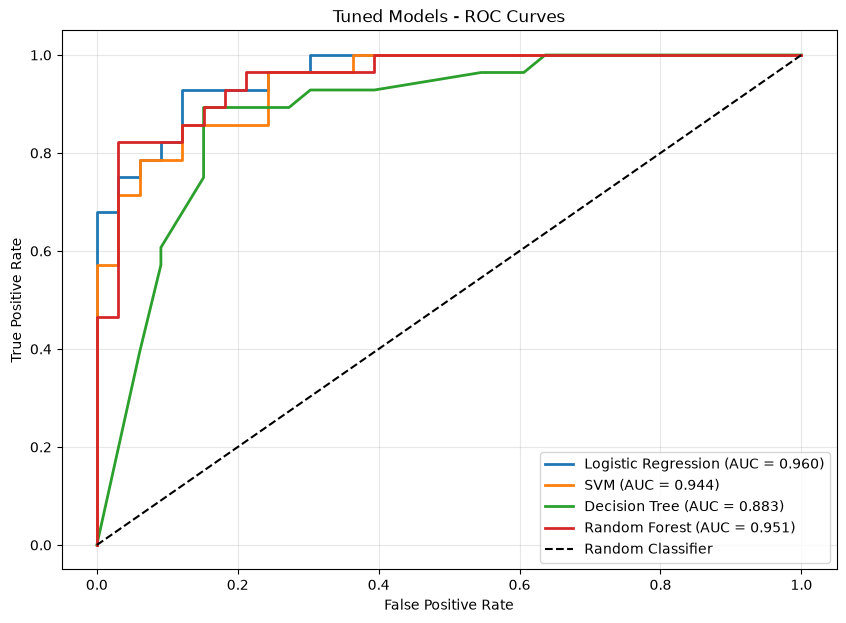

In [43]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))

for name, y_prob in final_predictions.items():

    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{name} (AUC = {roc_auc:.3f})"
    )

plt.plot([0, 1], [0, 1], "k--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Tuned Models - ROC Curves")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

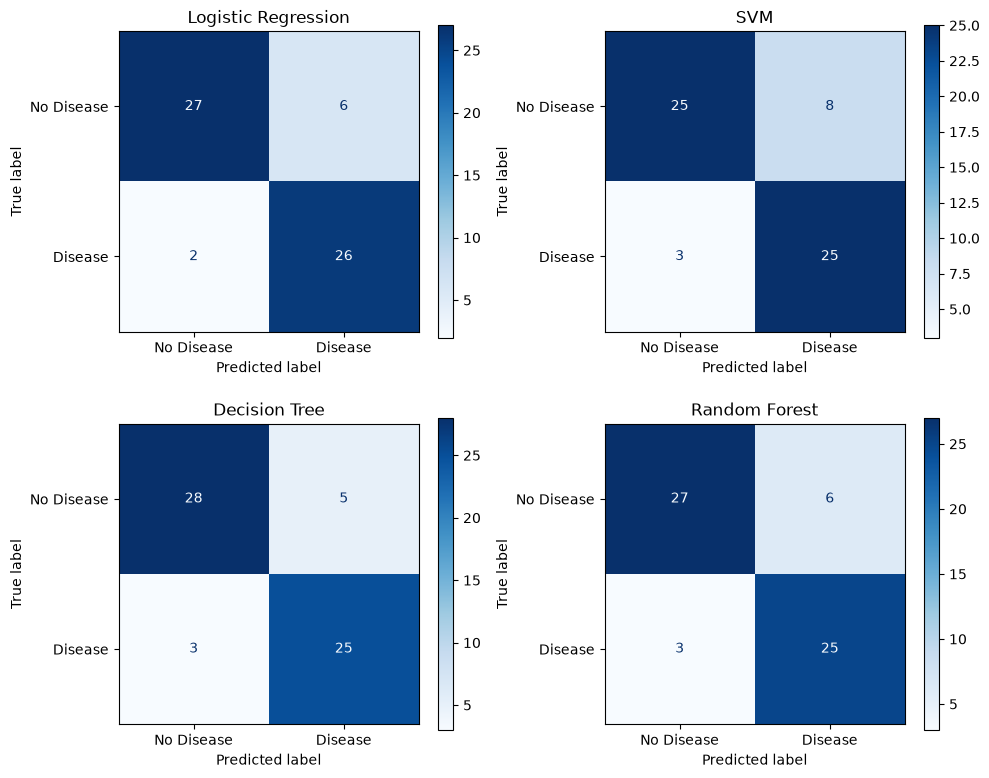

In [44]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(10, 8))

for ax, (name, model) in zip(axes.ravel(), best_models.items()):
    y_pred = model.predict(X_test)

    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred,
        display_labels=["No Disease", "Disease"],
        cmap="Blues",
        ax=ax
    )

    ax.set_title(name)

plt.tight_layout()
plt.show()

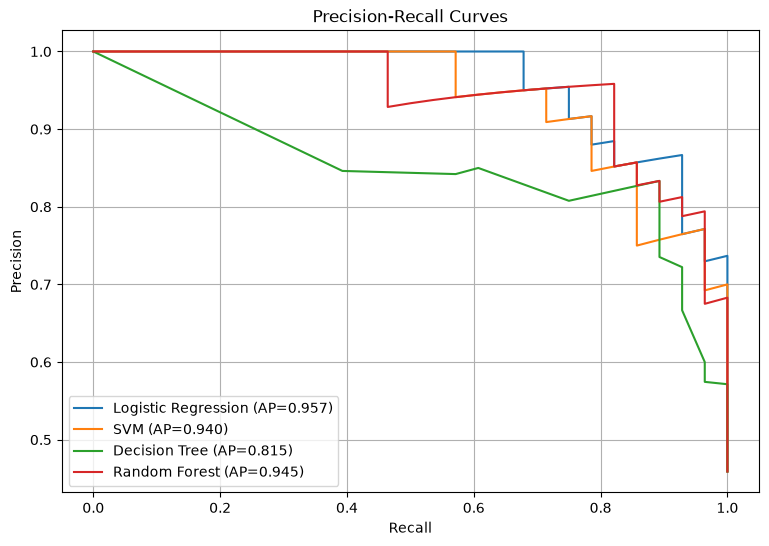

In [45]:
from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score
)
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

for name, model in best_models.items():
    y_prob = model.predict_proba(X_test)[:, 1]

    precision, recall, _ = precision_recall_curve(
        y_test, y_prob
    )

    ap = average_precision_score(y_test, y_prob)

    plt.plot(recall, precision, label=f"{name} (AP={ap:.3f})")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curves")
plt.legend()
plt.grid()
plt.show()

In [50]:

threshold_results = []

thresholds = [0.2, 0.3, 0.4, 0.5, 0.6, 0.7]

for name, model in best_models.items():
    y_prob = model.predict_proba(X_test)[:, 1]

    for threshold in thresholds:
        y_pred = (y_prob >= threshold).astype(int)

        threshold_results.append({
            "Model": name,
            "Threshold": threshold,
            "Precision": precision_score(y_test, y_pred, zero_division=0),
            "Recall": recall_score(y_test, y_pred, zero_division=0),
            "F1": f1_score(y_test, y_pred, zero_division=0)
        })

threshold_df = pd.DataFrame(threshold_results)

threshold_df.sort_values(
    ["Model", "Threshold"],
    inplace=True
)

print(threshold_df.round(3))

                  Model  Threshold  Precision  Recall     F1
12        Decision Tree        0.2      0.722   0.929  0.812
13        Decision Tree        0.3      0.722   0.929  0.812
14        Decision Tree        0.4      0.722   0.929  0.812
15        Decision Tree        0.5      0.781   0.893  0.833
16        Decision Tree        0.6      0.833   0.893  0.862
17        Decision Tree        0.7      0.808   0.750  0.778
0   Logistic Regression        0.2      0.683   1.000  0.812
1   Logistic Regression        0.3      0.737   1.000  0.848
2   Logistic Regression        0.4      0.765   0.929  0.839
3   Logistic Regression        0.5      0.812   0.929  0.867
4   Logistic Regression        0.6      0.862   0.893  0.877
5   Logistic Regression        0.7      0.917   0.786  0.846
18        Random Forest        0.2      0.636   1.000  0.778
19        Random Forest        0.3      0.675   0.964  0.794
20        Random Forest        0.4      0.750   0.964  0.844
21        Random Forest 

/tmp/ipykernel_9736/99223156.py:21: Pandas4Warning: The inplace keyword in DataFrame.sort_values is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  threshold_df.sort_values(


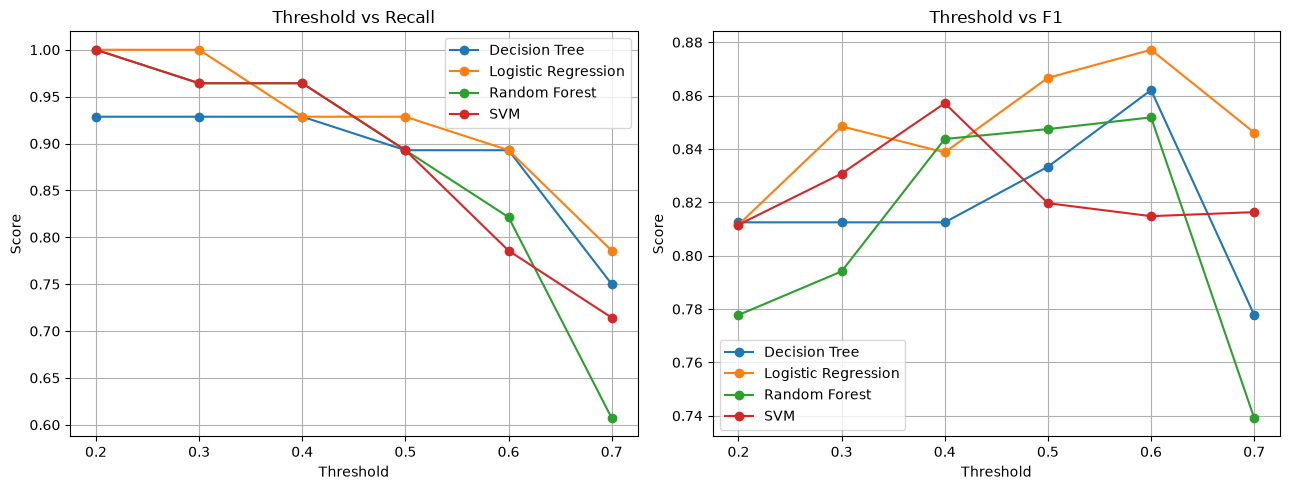

In [48]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for name, group in threshold_df.groupby("Model"):
    axes[0].plot(
        group["Threshold"], group["Recall"],
        marker="o", label=name
    )

    axes[1].plot(
        group["Threshold"], group["F1"],
        marker="o", label=name
    )

axes[0].set_title("Threshold vs Recall")
axes[1].set_title("Threshold vs F1")

for ax in axes:
    ax.set_xlabel("Threshold")
    ax.set_ylabel("Score")
    ax.legend()
    ax.grid()

plt.tight_layout()
plt.show()

In [49]:
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate

cv_repeated = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=10,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

for name, model in best_models.items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv_repeated,
        scoring=scoring
    )

    print(f"\n{name}")
    for metric in scoring:
        values = scores[f"test_{metric}"]
        print(f"{metric}: {values.mean():.3f} ± {values.std():.3f}")


Logistic Regression
accuracy: 0.820 ± 0.048
precision: 0.823 ± 0.075
recall: 0.784 ± 0.073
f1: 0.800 ± 0.053
roc_auc: 0.896 ± 0.033


/home/archit/Documents/CodeAlphaInternship/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/archit/Documents/CodeAlphaInternship/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/archit/Documents/CodeAlphaInternship/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/archit/Documents/CodeAlphaInternship/.venv/lib/python3.12/site-p


SVM
accuracy: 0.805 ± 0.050
precision: 0.813 ± 0.072
recall: 0.755 ± 0.080
f1: 0.780 ± 0.059
roc_auc: 0.882 ± 0.040

Decision Tree
accuracy: 0.783 ± 0.050
precision: 0.787 ± 0.074
recall: 0.735 ± 0.094
f1: 0.755 ± 0.060
roc_auc: 0.843 ± 0.051

Random Forest
accuracy: 0.813 ± 0.043
precision: 0.818 ± 0.066
recall: 0.771 ± 0.066
f1: 0.791 ± 0.046
roc_auc: 0.898 ± 0.035


In [52]:

from sklearn.model_selection import StratifiedKFold, cross_val_predict
selected_models = {
    "Logistic Regression": best_models["Logistic Regression"],
    "Random Forest": best_models["Random Forest"]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

oof_probabilities = {}

for name, model in selected_models.items():

    probabilities = cross_val_predict(
        model,
        X_train,
        y_train,
        cv=cv,
        method="predict_proba",
        n_jobs=-1
    )[:, 1]

    oof_probabilities[name] = probabilities

In [53]:
threshold_results = []

thresholds = np.arange(0.20, 0.81, 0.01)

for name, probabilities in oof_probabilities.items():

    for threshold in thresholds:

        predictions = (probabilities >= threshold).astype(int)

        precision = precision_score(
            y_train, predictions, zero_division=0
        )

        recall = recall_score(
            y_train, predictions, zero_division=0
        )

        f1 = f1_score(
            y_train, predictions, zero_division=0
        )

        objective = 0.4 * f1 + 0.6 * recall

        threshold_results.append({
            "Model": name,
            "Threshold": threshold,
            "Precision": precision,
            "Recall": recall,
            "F1": f1,
            "Objective": objective
        })

threshold_df = pd.DataFrame(threshold_results)

best_thresholds = (
    threshold_df.loc[
        threshold_df.groupby("Model")["Objective"].idxmax()
    ].reset_index(drop=True)
)

print(best_thresholds.round(4))

                 Model  Threshold  Precision  Recall      F1  Objective
0  Logistic Regression       0.21     0.6310   0.955  0.7599     0.8769
1        Random Forest       0.20     0.5759   0.991  0.7285     0.8860


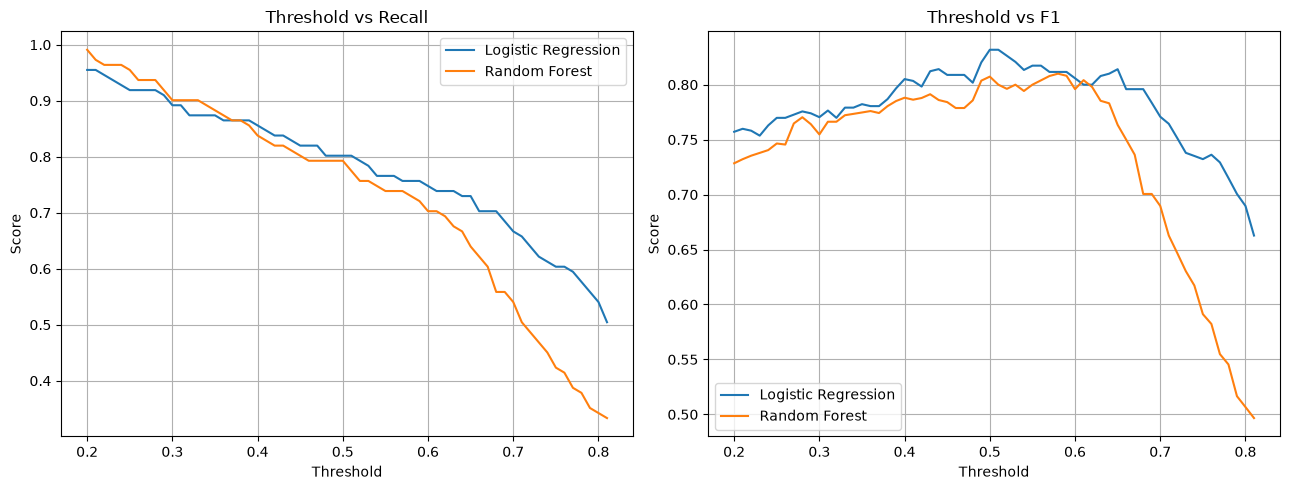

In [54]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for name, group in threshold_df.groupby("Model"):

    axes[0].plot(
        group["Threshold"],
        group["Recall"],
        label=name
    )

    axes[1].plot(
        group["Threshold"],
        group["F1"],
        label=name
    )

axes[0].set_title("Threshold vs Recall")
axes[1].set_title("Threshold vs F1")

for ax in axes:
    ax.set_xlabel("Threshold")
    ax.set_ylabel("Score")
    ax.legend()
    ax.grid()

plt.tight_layout()
plt.show()

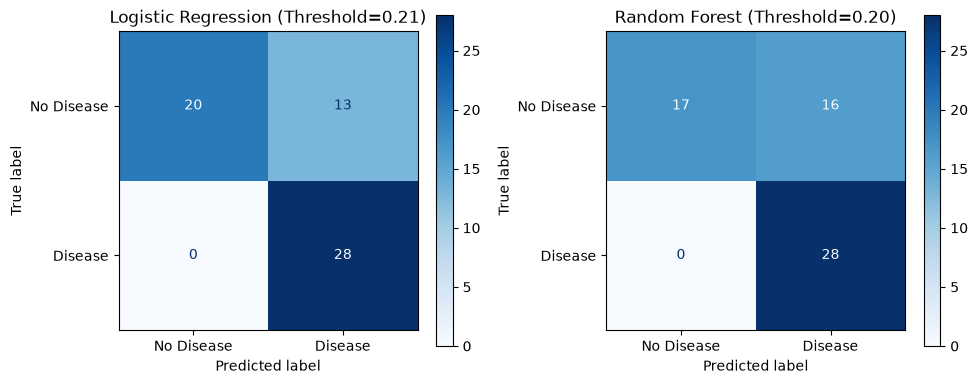

                 Model  Threshold  Accuracy  Precision  Recall      F1  \
0  Logistic Regression       0.21    0.7869     0.6829     1.0  0.8116   
1        Random Forest       0.20    0.7377     0.6364     1.0  0.7778   

   ROC-AUC  
0   0.9600  
1   0.9513  


In [55]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

final_results = []

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, (name, model) in zip(axes, selected_models.items()):

    threshold = best_thresholds.loc[
        best_thresholds["Model"] == name,
        "Threshold"
    ].iloc[0]

    probabilities = model.predict_proba(X_test)[:, 1]

    predictions = (probabilities >= threshold).astype(int)

    final_results.append({
        "Model": name,
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1": f1_score(y_test, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    })

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions,
        display_labels=["No Disease", "Disease"],
        cmap="Blues",
        ax=ax
    )

    ax.set_title(f"{name} (Threshold={threshold:.2f})")

plt.tight_layout()
plt.show()

final_df = pd.DataFrame(final_results)

print(final_df.round(4))

In [59]:
import joblib
import os

os.makedirs("../models", exist_ok=True)

for name, model in best_models.items():

    filename = name.lower().replace(" ", "_") + ".pkl"

    joblib.dump(
        model,
        f"../models/{filename}"
    )